<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-12/lab-070d-qgrnn.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 070d. A quantum graph recurrent neural network learns a hidden Hamiltonian

A quantum device holds four interacting qubits. Their Hamiltonian is of Ising type on a small graph, but the couplings between the qubits, the local fields and even the graph itself are hidden from us. We can prepare a few low-energy states on the device, let them evolve for a chosen time and hand the evolved state to a quantum computer. From such quantum data we want to recover the Hamiltonian. The model we train is a quantum graph recurrent neural network (QGRNN) [1], a circuit that repeats one Trotter step of a trial Hamiltonian on a graph with the same trainable parameters in every step.

| | The task of this notebook |
|---|---|
| **Unknown** | an Ising-type Hamiltonian on $N=4$ qubits, $\hat{\mathcal H}=\sum_{(i,j)\in E}J_{ij}\hat Z_i\hat Z_j+\sum_i\big(h_i\hat Z_i+g\hat X_i\big)$, with hidden couplings $J_{ij}$, hidden fields $h_i$ and hidden edge set $E$. The transverse field $g=1$ is known. |
| **Data** | pairs $\big(|\psi_m\rangle,\ |\psi_m(t)\rangle=e^{-i\hat{\mathcal H}t}|\psi_m\rangle\big)$ produced by the device, for $M=3$ low-energy initial states and five times each |
| **Model** | QGRNN, a Trotter layer $e^{-i\delta\hat{\mathcal H}_E(\boldsymbol\theta)}e^{-i\delta\hat{\mathcal H}_V(\boldsymbol\theta)}$ repeated $t/\delta$ times with trainable couplings and fields $\boldsymbol\theta$ on the complete graph of four qubits |
| **Loss** | $1-\bar F$, one minus the average fidelity between the model output and the data state |
| **Success** | the learned $J_{ij}$ and $h_i$ match the hidden ones, and the learned couplings vanish on pairs without an edge, so the learned graph reveals the hidden one |

All results are exact state-vector simulations in which we play both the device and the learner. The learner never reads the hidden parameters, which we use only to produce the data and to grade the result. On hardware the fidelities would be estimated from measured bit strings of a SWAP test, which we explain in Section 6. Sections 1 to 8 form the classroom route and run in well under a minute on a laptop CPU. Section 9 is an optional study of the amount of data and of the Trotter step, Section 10 lists exercises and Section 11 summarises.

## The QGRNN in seven steps

This overview follows the whole notebook in one pass. The later sections implement each step.

1. **The physical situation.** A device or material evolves its qubits under an unknown Hamiltonian $\hat{\mathcal H}_{\rm true}$. We can prepare a known initial state $|\psi_0\rangle$, let the system evolve for a time $t$ and keep the output $|\psi(t)\rangle=e^{-i\hat{\mathcal H}_{\rm true}t}|\psi_0\rangle$. Such output states are *quantum data*: we never see their amplitudes, only copies that can enter further circuits.
2. **The model as a hypothesis.** We write a family of Hamiltonians $\hat{\mathcal H}(\boldsymbol\theta)=\sum_{i<j}J_{ij}\hat Z_i\hat Z_j+\sum_i(h_i\hat Z_i+g\hat X_i)$ with trainable couplings $J_{ij}$ and fields $h_i$. The couplings define a graph, qubits as nodes and $J_{ij}\neq0$ as edges. Because the graph is unknown, the model allows a coupling on every pair, and absent edges should come out as $J_{ij}\approx0$.
3. **From Hamiltonian to circuit.** A circuit cannot apply $e^{-i\hat{\mathcal H}(\boldsymbol\theta)t}$ directly, so the evolution is split into short steps, $e^{-i\hat{\mathcal H}t}\approx\big(e^{-i\delta\hat{\mathcal H}_E}e^{-i\delta\hat{\mathcal H}_V}\big)^{t/\delta}$, where $\hat{\mathcal H}_E$ collects the couplings (two-qubit gates) and $\hat{\mathcal H}_V$ the fields (one-qubit rotations). One such step is one layer $\hat U_\delta(\boldsymbol\theta)$, and the same layer with the same $\boldsymbol\theta$ is repeated $t/\delta$ times. *Graph* names the interaction pattern, *recurrent* the repeated identical layer, as in a recurrent network unrolled in time, and *neural network* the trainable parameters.
4. **Training.** A fresh copy of $|\psi_0\rangle$ runs through the circuit for $t/\delta$ layers and gives the model state $|\phi_{\boldsymbol\theta}(t)\rangle$. It is compared with the data state through the fidelity $F=|\langle\psi(t)|\phi_{\boldsymbol\theta}(t)\rangle|^2$, which a SWAP test measures on hardware because its ancilla returns 0 with probability $(1+F)/2$. The loss $1-\bar F$, averaged over random data times and several initial states, is minimised by gradient steps on $\boldsymbol\theta$.
5. **Why matching states recovers the Hamiltonian.** Expanding $e^{-i\hat{\mathcal H}t}|\psi_0\rangle=|\psi_0\rangle-it\hat{\mathcal H}|\psi_0\rangle-\tfrac{t^2}{2}\hat{\mathcal H}^2|\psi_0\rangle+\dots$ shows that agreement at many times fixes $\hat{\mathcal H}|\psi_0\rangle$, $\hat{\mathcal H}^2|\psi_0\rangle$ and higher powers, and several initial states fix $\hat{\mathcal H}$ itself. An exact eigenstate as $|\psi_0\rangle$ would only acquire a phase and carry no information, so we use approximate ground states. Too few data leave $\hat{\mathcal H}$ undetermined, as Section 9 shows with a single data pair.
6. **What limits the accuracy.** Even the true parameters do not reproduce the data exactly, because the Trotter steps approximate the evolution. The best fit therefore shifts the parameters by an amount proportional to $\delta$, and a smaller $\delta$ costs more layers. On hardware, shot noise in the SWAP test and the depth needed for long times add further limits.
7. **Relation to the rest of the lecture.** As in VQE, a circuit with trainable angles sits in a hybrid loop, but the loss compares with quantum data instead of minimising an energy. As for the anomaly detector and the QCNN, the states never leave the device. Unlike those, the trained parameters have a physical meaning, the learned Hamiltonian, which makes the QGRNN a method of Hamiltonian learning, the subject of the next lecture.


## 1. Double-precision arithmetic

We work in double precision on the CPU. JAX computes the circuits, the gradients and the training loop, NumPy and SciPy build the Hamiltonian and the exact time evolution, and Matplotlib draws the figures. Every random seed is fixed.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"          # small calculations, never the GPU
import json, time, itertools
from pathlib import Path
import numpy as np
import scipy.linalg as sla
import jax
import jax.numpy as jnp
from jax import lax
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)
TOL = 1e-10
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
NAVY, BLUE, ORANGE, GRAY, GREEN = "#002B5C", "#3E8FD0", "#D35A05", "#5A6270", "#1B7F36"
plt.rcParams.update({"font.size": 13, "axes.labelsize": 13, "xtick.labelsize": 12, "ytick.labelsize": 12,
                     "legend.fontsize": 11.5, "figure.figsize": (4.8, 3.2), "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.bbox": "tight", "pdf.fonttype": 42, "ps.fonttype": 42})
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=200)
started = time.perf_counter()
RESULTS = {}
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. Qubits on a graph

A graph is a set of nodes and a set of edges, each edge joining two nodes. For a register of qubits the graph records which qubits interact, with one node per qubit and one edge for every pair of qubits coupled by the Hamiltonian. In our task the device is a ring of four qubits, but the learner does not know this. The learner therefore allows a coupling on every one of the six pairs, the complete graph of four nodes, and lets the data decide which couplings are zero. A pair whose learned coupling vanishes has no edge, so learning the couplings also learns the graph.

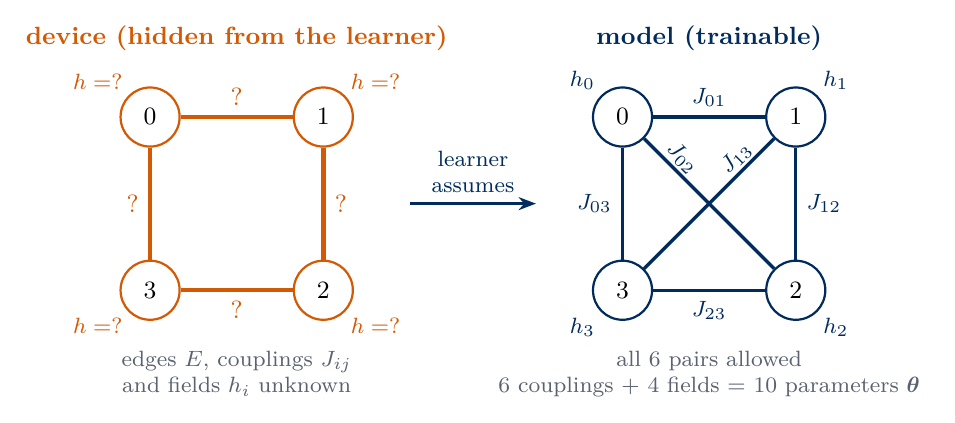

The sketch shows the device on the left, with its ring of edges and the unknown values marked by question marks, and the model on the right, with a trainable coupling $J_{ij}$ on every pair and a trainable field $h_i$ on every qubit, ten parameters in total.

## 3. The hidden Hamiltonian on a graph

The device holds $N=4$ qubits with the Hamiltonian
$$\hat{\mathcal H}=\underbrace{\sum_{(i,j)\in E}J_{ij}\,\hat Z_i\hat Z_j}_{\hat{\mathcal H}_E}\;+\;\underbrace{\sum_{i=0}^{N-1}\big(h_i\hat Z_i+g\,\hat X_i\big)}_{\hat{\mathcal H}_V} , \tag{1}$$
the transverse-field Ising model on a graph with edge set $E$, as in Ref. [1]. Here $\hat Z_i$ and $\hat X_i$ are Pauli operators on qubit $i$, $J_{ij}$ is the coupling on edge $(i,j)$, positive for an antiferromagnetic and negative for a ferromagnetic bond, $h_i$ is a longitudinal field on qubit $i$, and $g$ is the transverse field. We call $\hat{\mathcal H}_E$ the edge part and $\hat{\mathcal H}_V$ the node part. All terms of $\hat{\mathcal H}_E$ are diagonal in the computational basis and commute with one another, and so do the node terms of different qubits, but the edge and node parts do not commute.

The hidden graph is the ring $0-1-2-3-0$ of Section 2, so the pairs $(0,2)$ and $(1,3)$ carry no coupling. The learner only knows that there are four qubits, that the Hamiltonian has the form (1) on *some* graph, and that $g=1$. We collect all six possible couplings and the four fields in one parameter vector $\boldsymbol\theta=(J_{01},J_{02},J_{03},J_{12},J_{13},J_{23},h_0,h_1,h_2,h_3)$ of length 10, in which the hidden values of $J_{02}$ and $J_{13}$ are zero. The cell builds $\hat{\mathcal H}$ as a $16\times16$ matrix from Kronecker products, with qubit 0 as the leftmost factor, and checks that its diagonal agrees with the energies $\sum J_{ij}z_iz_j+\sum h_iz_i$ of the basis states, $z_i=\pm1$.

In [2]:
N, G_FIELD = 4, 1.0
PAIRS = list(itertools.combinations(range(N), 2))           # all 6 pairs = complete graph
NE = len(PAIRS)
J_HIDDEN = {(0, 1): 0.8, (1, 2): -1.1, (2, 3): 0.6, (0, 3): 1.2}   # ring 0-1-2-3-0, only the device knows this
H_HIDDEN = np.array([0.5, -0.4, 0.7, -0.6])
THETA_HIDDEN = np.concatenate([[J_HIDDEN.get(p, 0.0) for p in PAIRS], H_HIDDEN])
EDGE = np.array([p in J_HIDDEN for p in PAIRS])
LABELS = [f"$J_{{{i}{j}}}$" for i, j in PAIRS] + [f"$h_{{{q}}}$" for q in range(N)]

X = np.array([[0., 1.], [1., 0.]]); Z = np.diag([1., -1.]); I2 = np.eye(2)
def op_on(ops):
    # Kronecker product with ops[q] on qubit q and the identity elsewhere; qubit 0 is the leftmost factor
    out = np.eye(1)
    for q in range(N):
        out = np.kron(out, ops.get(q, I2))
    return out

BITS = np.array(list(itertools.product([0, 1], repeat=N)))   # basis index = b_0 b_1 b_2 b_3 in binary
ZB = 1 - 2 * BITS                                             # z_q = +1 for bit 0, -1 for bit 1
ZZB = np.stack([ZB[:, i] * ZB[:, j] for i, j in PAIRS], 1)    # z_i z_j of every basis state and pair

def hamiltonian(theta):
    # equation (1) as a dense matrix, built from Kronecker products
    H = sum(theta[k] * op_on({i: Z, j: Z}) for k, (i, j) in enumerate(PAIRS))
    H = H + sum(theta[NE + q] * op_on({q: Z}) + G_FIELD * op_on({q: X}) for q in range(N))
    return H.astype(complex)

H_TRUE = hamiltonian(THETA_HIDDEN)
assert np.allclose(np.diag(H_TRUE).real, ZZB @ THETA_HIDDEN[:NE] + ZB @ H_HIDDEN, atol=TOL)
E_TRUE, V_TRUE = np.linalg.eigh(H_TRUE)
print("hidden couplings:", {f"J{i}{j}": J_HIDDEN.get((i, j), 0.0) for i, j in PAIRS})
print("hidden fields   :", H_HIDDEN)
print(f"lowest energies E0 = {E_TRUE[0]:.3f}, E1 = {E_TRUE[1]:.3f}, gap = {E_TRUE[1] - E_TRUE[0]:.3f}")

hidden couplings: {'J01': 0.8, 'J02': 0.0, 'J03': 1.2, 'J12': -1.1, 'J13': 0.0, 'J23': 0.6}
hidden fields   : [ 0.5 -0.4  0.7 -0.6]
lowest energies E0 = -5.658, E1 = -4.107, gap = 1.551


## 4. One recurrent layer is one Trotter step

The state $|\psi(t)\rangle=e^{-i\hat{\mathcal H}t}|\psi_0\rangle$ cannot be produced gate by gate directly, because $\hat{\mathcal H}_E$ and $\hat{\mathcal H}_V$ do not commute and $e^{-i(\hat{\mathcal H}_E+\hat{\mathcal H}_V)t}\neq e^{-i\hat{\mathcal H}_Et}e^{-i\hat{\mathcal H}_Vt}$. For a short time $\delta$ the difference is small, and the product formula of Trotter [2]
$$e^{-i\hat{\mathcal H}t}=\lim_{P\to\infty}\Big(e^{-i\delta\hat{\mathcal H}_E}\,e^{-i\delta\hat{\mathcal H}_V}\Big)^{P},\qquad \delta=t/P , \tag{2}$$
replaces the evolution by $P$ short alternating steps, each built from simple gates. The edge factor $e^{-i\delta\hat{\mathcal H}_E}=\prod_{(i,j)}e^{-i\delta J_{ij}\hat Z_i\hat Z_j}$ is a product of two-qubit $\hat R_{zz}$ gates with angles $2\delta J_{ij}$, and since it is diagonal it multiplies the amplitude of basis state $b$ by the phase $e^{-i\delta\sum J_{ij}z_iz_j}$. The node factor is a product of single-qubit gates $\hat V_i=e^{-i\delta(h_i\hat Z_i+g\hat X_i)}$, one per qubit. With $\hat A=h\hat Z+g\hat X$ and $\hat A^2=(h^2+g^2)\hat I$ the exponential is $\hat V=\cos(\delta w)\,\hat I-i\sin(\delta w)\,\hat A/w$, $w=\sqrt{h^2+g^2}$.

A QGRNN layer is this Trotter step with *trainable* couplings and fields,
$$\hat U_\delta(\boldsymbol\theta)=e^{-i\delta\hat{\mathcal H}_E(\boldsymbol\theta)}\,e^{-i\delta\hat{\mathcal H}_V(\boldsymbol\theta)},\qquad |\phi_{\boldsymbol\theta}(t)\rangle=\hat U_\delta(\boldsymbol\theta)^{P}\,|\psi_0\rangle,\quad P=t/\delta , \tag{3}$$
where $\hat{\mathcal H}_E(\boldsymbol\theta)$ contains all six pairs of the complete graph. The same parameters enter every layer, and the number of layers is set by the time we want to reach. A recurrent neural network applies one cell with the same weights at every step of a sequence. The QGRNN does the same with one Trotter layer at every time step, so its trajectory is a recurrent network unrolled in time. In the name, *graph* refers to the pattern of interacting qubits, *recurrent* to the identical layer that is repeated, and *neural network* to the trainable parameters fitted to data. If the model parameters equal the hidden ones, the QGRNN output approximates the true evolution with an error that vanishes as $\delta\to0$. The step is fixed at $\delta=0.05$, a hyperparameter of the model. The sketch shows the whole construction, from the graph to the Hamiltonian, the repeated layer and the comparison with data that Section 6 explains.

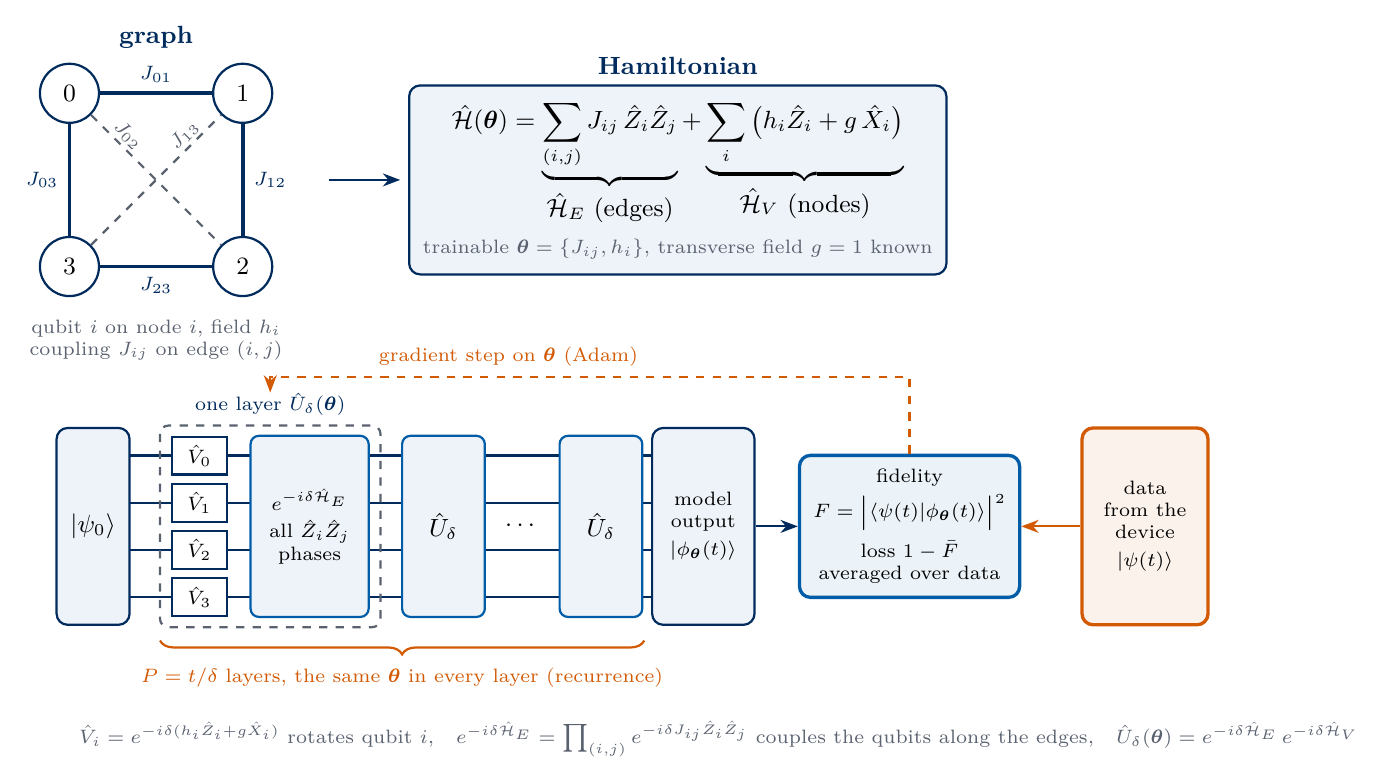

The code stores the state as a tensor with one index per qubit, applies $\hat V_i$ on qubit $i$ with `tensordot`, and multiplies by the diagonal edge phases. The `lax.scan` loop applies the layer $P$ times and returns the state after every layer, the trajectory $|\phi_{\boldsymbol\theta}(k\delta)\rangle$, $k=1,\dots,P$, so one run serves all data times at once. We check one layer against the matrix exponentials of the Kronecker-product Hamiltonians.

In [3]:
DELTA = 0.05

def node_gates(h, delta=DELTA):
    # V_i = exp(-i delta (h_i Z + g X)) = cos(delta w) I - i sin(delta w) (h_i Z + g X)/w, w = sqrt(h_i^2 + g^2)
    w = jnp.sqrt(h ** 2 + G_FIELD ** 2)
    c, s = jnp.cos(delta * w), jnp.sin(delta * w) / w
    return c[:, None, None] * jnp.eye(2) - 1j * s[:, None, None] * (h[:, None, None] * Z + G_FIELD * X)

def qgrnn_layer(psi, J, V, delta=DELTA):
    # equation (3): node gates on every qubit, then the diagonal edge phases exp(-i delta sum J_ij z_i z_j)
    t = psi.reshape((2,) * N)
    for q in range(N):
        t = jnp.moveaxis(jnp.tensordot(V[q], t, axes=([1], [q])), 0, q)
    return t.reshape(-1) * jnp.exp(-1j * delta * (ZZB @ J))

def trajectory(theta, psi0, n_layers, delta=DELTA):
    # states after 1, 2, ..., n_layers layers; the same theta in every layer
    J, V = theta[:NE], node_gates(theta[NE:], delta)
    def body(psi, _):
        psi = qgrnn_layer(psi, J, V, delta)
        return psi, psi
    return lax.scan(body, jnp.asarray(psi0, dtype=complex), None, length=n_layers)[1]

# check one layer against expm of the Kronecker-product matrices
rng = np.random.default_rng(1)
th_r = rng.normal(size=NE + N)
psi_r = rng.normal(size=2 ** N) + 1j * rng.normal(size=2 ** N); psi_r /= np.linalg.norm(psi_r)
HE = hamiltonian(np.concatenate([th_r[:NE], np.zeros(N)])) - G_FIELD * sum(op_on({q: X}) for q in range(N))
HV = hamiltonian(th_r) - HE
ref = sla.expm(-1j * DELTA * HE) @ sla.expm(-1j * DELTA * HV) @ psi_r
assert np.allclose(qgrnn_layer(jnp.asarray(psi_r), jnp.asarray(th_r[:NE]), node_gates(jnp.asarray(th_r[NE:]))), ref, atol=1e-12)
assert np.linalg.norm(HE @ HV - HV @ HE) > 1                 # the two parts do not commute

# Trotter error with the hidden parameters: QGRNN output vs exact evolution of the ground state
t_layers = np.arange(1, 31) * DELTA
traj = np.asarray(trajectory(jnp.asarray(THETA_HIDDEN), V_TRUE[:, 0], 30))
exact = np.array([sla.expm(-1j * t * H_TRUE) @ V_TRUE[:, 0] for t in t_layers])
inf_trotter = 1 - np.abs(np.sum(exact.conj() * traj, 1)) ** 2
print(f"infidelity of the Trotterised evolution at t = 0.5, 1.0, 1.5: {inf_trotter[[9, 19, 29]]}")

infidelity of the Trotterised evolution at t = 0.5, 1.0, 1.5: [0.00301712 0.00075525 0.00284696]


With the hidden parameters the QGRNN reproduces the exact evolution of the ground state with an infidelity below $4\times10^{-3}$ for all thirty layers. This Trotter error is part of the model, and in Section 8 we will see how it biases the learned parameters.

## 5. Quantum data from the device

The device prepares low-energy states. An eigenstate of $\hat{\mathcal H}$ would be useless, because it only acquires a global phase, $e^{-i\hat{\mathcal H}t}|E_n\rangle=e^{-iE_nt}|E_n\rangle$, and every Hamiltonian with the same eigenvector reproduces this "evolution" perfectly. A useful initial state must therefore be a superposition of several eigenstates, whose relative phases $e^{-i(E_n-E_m)t}$ carry the information about the energy differences. We model an imperfect cooling of the device by preparing the exact ground state $|E_0\rangle$ and then rotating every qubit by a small random angle $\varepsilon_{m,q}\in[0.2,0.6]$ about the $y$ axis,
$$|\psi_m\rangle=\prod_{q=0}^{N-1}\hat R_y(\varepsilon_{m,q})\,|E_0\rangle,\qquad m=1,2,3 . \tag{4}$$
Each of the $M=3$ initial states is then evolved exactly, $|\psi_m(t)\rangle=e^{-i\hat{\mathcal H}t}|\psi_m\rangle$, at five times drawn from the grid $t\in\{0.1,0.2,\dots,1.5\}$. The data set consists of these $M\times5=15$ pairs. The learner receives only copies of the states and knows neither their amplitudes nor how they were made.

state 1: <H> = -5.213 (E0 = -5.658), weight on |E0> = 0.874, times = [0.2 0.4 0.8 1.1 1.3]
state 2: <H> = -5.118 (E0 = -5.658), weight on |E0> = 0.837, times = [0.3 0.5 0.6 1.3 1.5]
state 3: <H> = -4.723 (E0 = -5.658), weight on |E0> = 0.765, times = [0.2 0.4 0.6 1.  1.3]


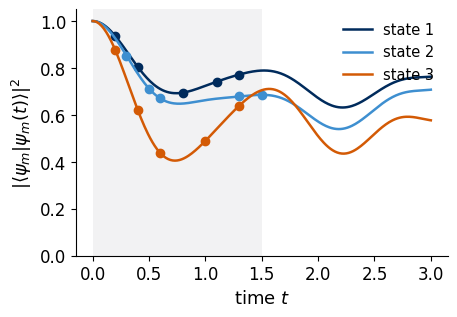

In [4]:
M, K_PER = 3, 5
T_GRID = np.round(np.arange(1, 16) * 0.1, 10)                 # 0.1, 0.2, ..., 1.5
rng = np.random.default_rng(2026)
def ry(a):
    c, s = np.cos(a / 2), np.sin(a / 2)
    return np.array([[c, -s], [s, c]])
EPS = rng.uniform(0.2, 0.6, size=(M, N))
PSI0 = np.array([op_on({q: ry(EPS[m, q]) for q in range(N)}) @ V_TRUE[:, 0] for m in range(M)])   # equation (4)
TIMES = np.array([np.sort(rng.choice(T_GRID, K_PER, replace=False)) for _ in range(M)])
DATA = np.array([[sla.expm(-1j * t * H_TRUE) @ PSI0[m] for t in TIMES[m]] for m in range(M)])
STEPS = np.rint(TIMES / DELTA).astype(int)                    # number of QGRNN layers for every data time
assert np.allclose(STEPS * DELTA, TIMES, atol=TOL)

E_INIT = np.array([np.real(p.conj() @ H_TRUE @ p) for p in PSI0])
P_GS = np.abs(PSI0 @ V_TRUE[:, 0].conj()) ** 2
for m in range(M):
    print(f"state {m + 1}: <H> = {E_INIT[m]:.3f} (E0 = {E_TRUE[0]:.3f}), weight on |E0> = {P_GS[m]:.3f}, times = {TIMES[m]}")

# survival probability |<psi_m|psi_m(t)>|^2 as a picture of the data
t_fine = np.linspace(0, 3, 301)
EXPS = np.exp(-1j * np.outer(t_fine, E_TRUE))
def exact_evolution(psi):
    c = V_TRUE.conj().T @ psi
    return (EXPS * c) @ V_TRUE.T                              # rows: e^{-iHt}|psi> on the fine grid
fig, ax = plt.subplots(figsize=(4.8, 3.2))
for m, col in zip(range(M), (NAVY, BLUE, ORANGE)):
    surv = np.abs(exact_evolution(PSI0[m]) @ PSI0[m].conj()) ** 2
    ax.plot(t_fine, surv, color=col, lw=1.8, label=f"state {m + 1}")
    ax.plot(TIMES[m], np.abs(DATA[m] @ PSI0[m].conj()) ** 2, "o", color=col, ms=6)
ax.axvspan(0, 1.5, color=GRAY, alpha=0.08, lw=0)
ax.set_xlabel("time $t$"); ax.set_ylabel(r"$|\langle\psi_m|\psi_m(t)\rangle|^2$")
ax.legend(frameon=False, loc="upper right", fontsize=10.5); ax.set_ylim(0, 1.05)
save(fig, "fig_lab070d_data"); plt.show()
RESULTS["data"] = {"E0": E_TRUE[0], "E1": E_TRUE[1], "E_init": E_INIT.tolist(), "weight_E0": P_GS.tolist(),
                   "times": TIMES.tolist()}

The figure shows how far each initial state moves away from itself in time, with the data times as dots inside the grey window $t\le1.5$. The overlap oscillates, with frequencies set by the gaps between the eigenvalues that the initial state mixes. States 1 and 2 keep a weight above 0.8 on the ground state and their overlap falls to about 0.65, whereas state 3, the one with the highest energy, falls to about 0.4. All three are low-energy states, with mean energies between 0.3 and 0.6 of the gap above $E_0$, yet they change visibly within the time window. Each data pair compares one point of such a curve with the full quantum state, which carries far more information than the overlap drawn here.

## 6. Loss function and the SWAP test

For the pair with initial state $|\psi_m\rangle$ and time $t_{mk}$ the QGRNN runs $P_{mk}=t_{mk}/\delta$ layers on $|\psi_m\rangle$ and produces $|\phi_{\boldsymbol\theta}(t_{mk})\rangle$. Its *fidelity* with the data state, $F_{mk}=|\langle\psi_m(t_{mk})|\phi_{\boldsymbol\theta}(t_{mk})\rangle|^2$, is the probability that the model output passes a test for being the data state. It equals one when the two states agree up to a global phase. The loss is one minus the average fidelity over all pairs,
$$\mathcal L(\boldsymbol\theta)=1-\frac1{MK}\sum_{m=1}^{M}\sum_{k=1}^{K}\big|\langle\psi_m(t_{mk})|\,\hat U_\delta(\boldsymbol\theta)^{P_{mk}}\,|\psi_m\rangle\big|^2 , \tag{5}$$
with $K=5$ times per initial state. Ref. [1] uses the same loss.

A device does not output amplitudes, so the fidelity has to be measured. The SWAP test [3] does this with one extra qubit, the ancilla. The model output and the data state are loaded into two registers of $N$ qubits each, the ancilla starts in $|0\rangle$ and passes a Hadamard gate, a controlled-SWAP exchanges the two registers qubit by qubit when the ancilla is $|1\rangle$, and a second Hadamard gate precedes the measurement of the ancilla.

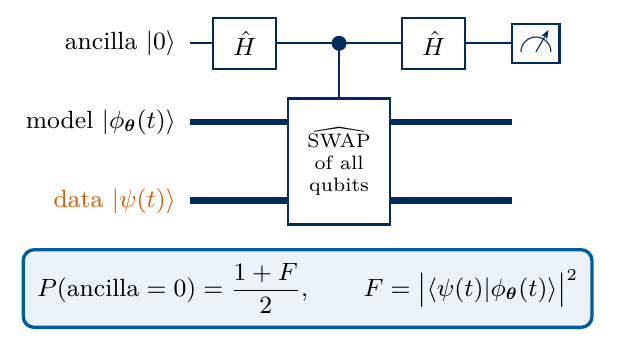

We follow the three registers through the circuit, writing $|a\rangle=|\phi_{\boldsymbol\theta}(t)\rangle$ for the model state and $|b\rangle=|\psi(t)\rangle$ for the data state.

1. Start: $|0\rangle|a\rangle|b\rangle$.
2. The Hadamard gate on the ancilla gives $\tfrac1{\sqrt2}\big(|0\rangle+|1\rangle\big)|a\rangle|b\rangle$.
3. The controlled-SWAP exchanges the registers only in the $|1\rangle$ branch: $\tfrac1{\sqrt2}\big(|0\rangle|a\rangle|b\rangle+|1\rangle|b\rangle|a\rangle\big)$.
4. The second Hadamard gate maps $|0\rangle\to(|0\rangle+|1\rangle)/\sqrt2$ and $|1\rangle\to(|0\rangle-|1\rangle)/\sqrt2$, so
$$\tfrac12|0\rangle\big(|a\rangle|b\rangle+|b\rangle|a\rangle\big)+\tfrac12|1\rangle\big(|a\rangle|b\rangle-|b\rangle|a\rangle\big).$$
5. The probability of reading 0 is the squared norm of the $|0\rangle$ branch. Expanding it with $\langle a|a\rangle=\langle b|b\rangle=1$ gives two norm terms equal to 1 and two cross terms $\langle a|b\rangle\langle b|a\rangle=|\langle a|b\rangle|^2$,
$$P(\text{ancilla}=0)=\tfrac14\big(1+1+2|\langle a|b\rangle|^2\big)=\tfrac12\big(1+|\langle\psi|\phi\rangle|^2\big)=\tfrac12(1+F) . \tag{6}$$

Identical states always give the outcome 0, orthogonal states give 0 and 1 with equal probability. The test needs only fresh copies of the two states and never their amplitudes, which is why it works on quantum data.

From $S$ repetitions with $n_0$ zeros the estimate is $\tilde F=2n_0/S-1$, with a statistical error of order $1/\sqrt S$. The cell simulates the SWAP test on $2N+1=9$ qubits for one data pair and checks equation (6). In the training we evaluate (5) exactly, as a simulation allows.

In [5]:
def swap_test_p0(phi, psi):
    # ancilla (qubit 0) + register A (phi) + register B (psi); returns P(ancilla = 0)
    n = 2 * N + 1
    state = np.kron(np.array([1, 0]), np.kron(phi, psi)).reshape((2,) * n)
    Hd = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
    state = np.moveaxis(np.tensordot(Hd, state, axes=([1], [0])), 0, 0)
    # controlled-SWAP of all qubit pairs (A_q, B_q): on the ancilla-1 branch swap the two register axes
    branch1 = state[1]
    branch1 = np.transpose(branch1, list(range(N, 2 * N)) + list(range(N)))
    state = np.stack([state[0], branch1])
    state = np.tensordot(Hd, state, axes=([1], [0]))
    return float(np.sum(np.abs(state[0]) ** 2))

phi_test = np.asarray(trajectory(jnp.zeros(NE + N), PSI0[0], STEPS[0, 2]))[-1]    # some model output
F_test = abs(np.vdot(DATA[0, 2], phi_test)) ** 2
p0 = swap_test_p0(phi_test, DATA[0, 2])
assert abs(p0 - (1 + F_test) / 2) < TOL                         # equation (6)
shots = np.random.default_rng(5).random(1000) < p0
print(f"F = {F_test:.4f}, P(ancilla=0) = {p0:.4f}, estimate from 1000 shots = {2 * shots.mean() - 1:.3f}")

def make_loss(psi0, data, steps, delta=DELTA):
    # equation (5); one QGRNN trajectory per initial state covers all its data times
    psi0, data = jnp.asarray(psi0, dtype=complex), jnp.asarray(data)
    n_layers = int(np.max(steps))
    def loss(theta):
        traj = jax.vmap(lambda p: trajectory(theta, p, n_layers, delta))(psi0)        # (M, layers, 2^N)
        out = traj[jnp.arange(psi0.shape[0])[:, None], jnp.asarray(steps) - 1]       # (M, K, 2^N)
        return 1.0 - jnp.mean(jnp.abs(jnp.sum(jnp.conj(data) * out, -1)) ** 2)
    return loss

loss = make_loss(PSI0, DATA, STEPS)
L_HIDDEN = float(loss(jnp.asarray(THETA_HIDDEN)))
print(f"loss at the hidden parameters (pure Trotter error): {L_HIDDEN:.2e}")

F = 0.1859, P(ancilla=0) = 0.5930, estimate from 1000 shots = 0.242


loss at the hidden parameters (pure Trotter error): 2.29e-03


## 7. Training

The learner starts from random couplings on all six pairs and random fields, each drawn uniformly from $[-0.5,0.5]$, so the initial guess is a dense graph with no resemblance to the hidden ring. JAX differentiates the loss (5) exactly through all layers, and Adam [4], written out in a few lines, updates the ten parameters with step size $0.05$ for 500 steps. Because the same parameter appears in every layer, its derivative is the sum of the contributions of all layers, which automatic differentiation adds up for us. On hardware each contribution would come from a parameter-shift pair of circuits, so one gradient of a coupling would need two circuits per occurrence of its gate, that is $2P$ circuits per data pair, each repeated for many shots.

We follow two numbers during training, the loss and the largest deviation $\max_k|\theta_k-\theta_k^{\rm hidden}|$ from the hidden parameters. Only the first is available to the learner, while the second grades the result.

training: 1.0 s, loss 0.493 -> 1.74e-03, max |theta - hidden| 1.17 -> 0.052


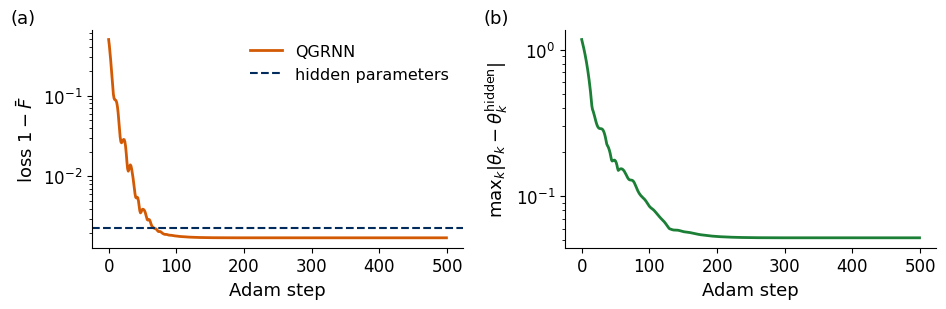

In [6]:
def adam(loss, theta, steps=500, lr=0.05, b1=0.9, b2=0.999, eps=1e-8):
    vg = jax.jit(jax.value_and_grad(loss))
    m, v = jnp.zeros_like(theta), jnp.zeros_like(theta)
    hist, err = [], []
    for k in range(1, steps + 1):
        L, g = vg(theta)
        hist.append(float(L)); err.append(float(jnp.max(jnp.abs(theta - THETA_HIDDEN))))
        m = b1 * m + (1 - b1) * g; v = b2 * v + (1 - b2) * g ** 2
        theta = theta - lr * (m / (1 - b1 ** k)) / (jnp.sqrt(v / (1 - b2 ** k)) + eps)
    return np.asarray(theta), np.array(hist), np.array(err), float(vg(theta)[0])

THETA0 = np.asarray(jax.random.uniform(jax.random.PRNGKey(0), (NE + N,), minval=-0.5, maxval=0.5))
t0 = time.perf_counter()
THETA, HIST, ERR, L_FINAL = adam(loss, jnp.asarray(THETA0))
print(f"training: {time.perf_counter() - t0:.1f} s, loss {HIST[0]:.3f} -> {L_FINAL:.2e}, "
      f"max |theta - hidden| {ERR[0]:.2f} -> {np.abs(THETA - THETA_HIDDEN).max():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.3))
ax[0].semilogy(HIST, color=ORANGE, lw=2, label="QGRNN")
ax[0].axhline(L_HIDDEN, color=NAVY, ls="--", lw=1.5, label="hidden parameters")
ax[0].set_xlabel("Adam step"); ax[0].set_ylabel(r"loss $1-\bar F$"); ax[0].legend(frameon=False)
ax[1].semilogy(ERR, color=GREEN, lw=2)
ax[1].set_xlabel("Adam step"); ax[1].set_ylabel(r"max$_k|\theta_k-\theta_k^{\rm hidden}|$")
for a, s in zip(ax, "ab"):
    a.text(-0.22, 1.03, f"({s})", transform=a.transAxes, fontsize=13)
fig.tight_layout(); save(fig, "fig_lab070d_training"); plt.show()

(a) The loss falls by more than two orders of magnitude within about one hundred steps and then settles. It ends *below* the dashed line, the loss of the hidden parameters themselves. (b) The parameter error falls from about one to a few hundredths and stays there. Both observations arise because the data come from the exact evolution, whereas the model is a Trotterised evolution, so the hidden parameters do not give the best possible match. The training finds slightly shifted parameters that partly compensate the Trotter error, and this shift is the remaining parameter error.

## 8. The learned Hamiltonian

We now compare the learned parameters with the hidden ones and draw the learned graph. In the graph drawing every one of the six pairs is drawn with a line width proportional to $|J_{ij}|$, orange for $J_{ij}>0$ and navy for $J_{ij}<0$, so a coupling close to zero appears as a hairline.

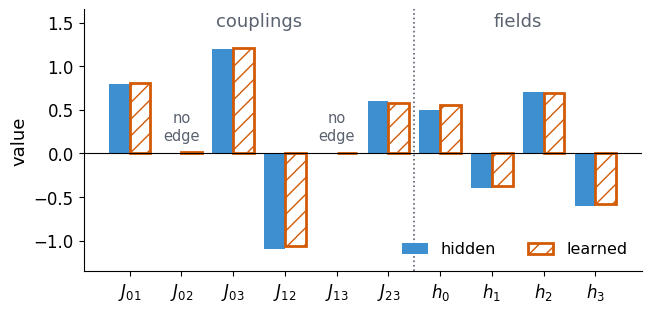

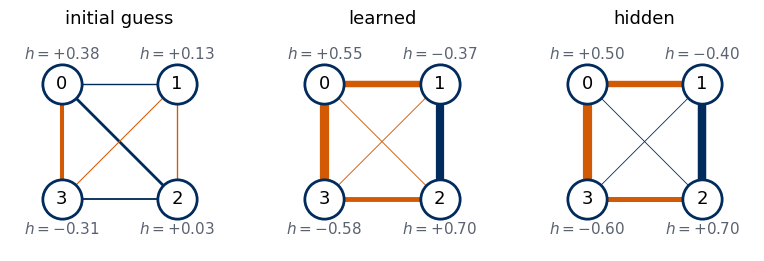

learned - hidden: {'J_{01}': np.float64(0.012), 'J_{02}': np.float64(0.011), 'J_{03}': np.float64(0.011), 'J_{12}': np.float64(0.034), 'J_{13}': np.float64(0.01), 'J_{23}': np.float64(-0.021), 'h_{0}': np.float64(0.052), 'h_{1}': np.float64(0.033), 'h_{2}': np.float64(-0.005), 'h_{3}': np.float64(0.02)}
largest |J| on the two pairs without an edge: 0.011; smallest |J| on the four edges: 0.579


In [7]:
DEV = THETA - THETA_HIDDEN
fig, ax = plt.subplots(figsize=(7.2, 3.4))
x = np.arange(NE + N)
ax.bar(x - 0.2, THETA_HIDDEN, 0.4, color=BLUE, label="hidden")
ax.bar(x + 0.2, THETA, 0.4, color="none", edgecolor=ORANGE, lw=2, hatch="//", label="learned")
ax.axhline(0, color="black", lw=0.8); ax.axvline(NE - 0.5, color=GRAY, ls=":", lw=1.2)
ax.set_xticks(x); ax.set_xticklabels(LABELS)
for i in np.where(~EDGE)[0]:
    ax.text(i, 0.12, "no\nedge", ha="center", va="bottom", fontsize=10.5, color=GRAY)
ax.text(2.5, 1.45, "couplings", ha="center", color=GRAY); ax.text(7.5, 1.45, "fields", ha="center", color=GRAY)
ax.set_ylabel("value"); ax.set_ylim(-1.35, 1.65); ax.legend(frameon=False, loc="lower right", ncol=2, handlelength=1.6)
save(fig, "fig_lab070d_parameters"); plt.show()

POS = np.array([[0, 1], [1, 1], [1, 0], [0, 0]], float)       # qubit 0 top left, then clockwise
def draw_graph(ax, th, title):
    for (i, j), w in zip(PAIRS, th[:NE]):
        ax.plot(*POS[[i, j]].T, color=ORANGE if w > 0 else NAVY, lw=0.6 + 5 * abs(w), zorder=1, solid_capstyle="round")
    for q in range(N):
        ax.scatter(*POS[q], s=800, color="white", edgecolor=NAVY, lw=2, zorder=2)
        ax.text(*POS[q], str(q), ha="center", va="center", fontsize=13, zorder=3)
        ax.text(POS[q, 0], POS[q, 1] + (0.26 if POS[q, 1] > 0.5 else -0.26), f"$h={th[NE + q]:+.2f}$",
                ha="center", va="center", fontsize=11, color=GRAY)
    ax.set_title(title, fontsize=13); ax.set_xlim(-0.45, 1.45); ax.set_ylim(-0.45, 1.45); ax.set_aspect("equal"); ax.axis("off")
fig, ax = plt.subplots(1, 3, figsize=(9.6, 3.4))
for a, th, title in zip(ax, (THETA0, THETA, THETA_HIDDEN), ("initial guess", "learned", "hidden")):
    draw_graph(a, th, title)
save(fig, "fig_lab070d_graphs"); plt.show()

print("learned - hidden:", dict(zip([l.strip("$") for l in LABELS], np.round(DEV, 3))))
print(f"largest |J| on the two pairs without an edge: {np.abs(THETA[:NE][~EDGE]).max():.3f}; "
      f"smallest |J| on the four edges: {np.abs(THETA[:NE][EDGE]).min():.3f}")

The learned couplings and fields agree with the hidden ones to within a few hundredths, the largest deviation being about $0.05$ on the field $h_0$. The two pairs without an edge, $(0,2)$ and $(1,3)$, end with couplings of order $10^{-2}$, whereas the four edges keep couplings of at least $0.58$ in magnitude. The learned graph is therefore the hidden ring, although the model was allowed every pair and started from a dense random graph. This is how the QGRNN can reveal the interaction graph of a device. If the graph were known in advance, training only the four ring couplings would be an easier problem.

To test the fit on dynamics it was not trained on, we evolve the three initial states with the learned QGRNN up to $t=3$, twice the longest data time, and compare with the exact evolution at every multiple of $\delta$.

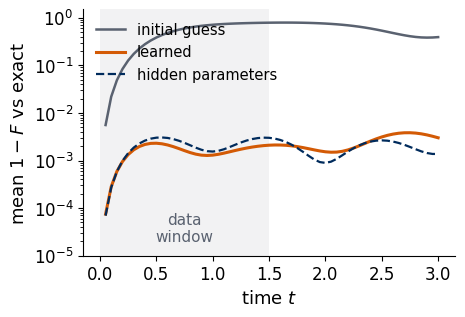

mean infidelity at t = 3: learned 3.0e-03, hidden parameters (Trotter) 1.4e-03, initial guess 0.39


In [8]:
t_pred = np.arange(1, 61) * DELTA
def prediction_infidelity(theta):
    out = []
    for m in range(M):
        model = np.asarray(trajectory(jnp.asarray(theta), PSI0[m], 60))
        exact = np.array([sla.expm(-1j * t * H_TRUE) @ PSI0[m] for t in t_pred])
        out.append(1 - np.abs(np.sum(exact.conj() * model, 1)) ** 2)
    return np.mean(out, 0)
PRED_INIT, PRED_LEARNED, PRED_HIDDEN = (prediction_infidelity(th) for th in (THETA0, THETA, THETA_HIDDEN))
fig, ax = plt.subplots(figsize=(4.8, 3.2))
ax.semilogy(t_pred, PRED_INIT, color=GRAY, lw=1.8, label="initial guess")
ax.semilogy(t_pred, PRED_LEARNED, color=ORANGE, lw=2.2, label="learned")
ax.semilogy(t_pred, PRED_HIDDEN, color=NAVY, ls="--", lw=1.6, label="hidden parameters")
ax.axvspan(0, 1.5, color=GRAY, alpha=0.08, lw=0); ax.text(0.75, 2e-5, "data\nwindow", ha="center", color=GRAY, fontsize=11)
ax.set_xlabel("time $t$"); ax.set_ylabel(r"mean $1-F$ vs exact"); ax.set_ylim(1e-5, 1.5)
ax.legend(frameon=False, loc="upper left", fontsize=10.5)
save(fig, "fig_lab070d_prediction"); plt.show()
print(f"mean infidelity at t = 3: learned {PRED_LEARNED[-1]:.1e}, hidden parameters (Trotter) {PRED_HIDDEN[-1]:.1e}, "
      f"initial guess {PRED_INIT[-1]:.2f}")

The grey curve shows that the random initial guess loses the state within a fraction of a time unit. The learned QGRNN follows the exact evolution with an infidelity of a few $10^{-3}$, also beyond the data window, where it was never trained. Its error stays within a factor of about two of the error of the Trotterised evolution with the hidden parameters (dashed), slightly below it inside the window and slightly above it later. The learned model is therefore nearly as good a simulator of the device as the step $\delta=0.05$ allows.

The Trotter step sets the accuracy of this result. The learned parameters are those of the best Trotterised model, which differ from the hidden ones by an amount proportional to $\delta$ (Section 9). The data must also be rich enough, because several initial states and several times are needed to fix ten parameters, as Section 9 shows with a smaller data set. Finally, everything here is exact, whereas on a device every fidelity is a SWAP-test estimate from a finite number of shots, every gradient component costs many circuits, and the device itself is noisy. The task solved here, recovering a Hamiltonian from the dynamics it generates, is called Hamiltonian learning [5], and the next lecture treats it with other methods.

In [9]:
RESULTS["main"] = {"N": N, "delta": DELTA, "pairs": M * K_PER, "loss_initial": HIST[0], "loss_final": L_FINAL,
                   "loss_hidden": L_HIDDEN, "theta_learned": THETA.tolist(), "theta_hidden": THETA_HIDDEN.tolist(),
                   "max_abs_error": float(np.abs(DEV).max()), "max_nonedge_J": float(np.abs(THETA[:NE][~EDGE]).max()),
                   "min_edge_J": float(np.abs(THETA[:NE][EDGE]).min()),
                   "prediction_t3": {"learned": PRED_LEARNED[-1], "hidden": PRED_HIDDEN[-1], "initial": PRED_INIT[-1]}}
RESULTS["classroom_seconds"] = time.perf_counter() - started
(RES / "lab070d_results.json").write_text(json.dumps(RESULTS, indent=2, default=float))
print(f"classroom route (Sections 1-8): {RESULTS['classroom_seconds']:.0f} s")

classroom route (Sections 1-8): 7 s


## 9. Optional. How much data, and how small a Trotter step

We first train the same model from the same start on three smaller data sets, one pair (state 1 at its first time), five pairs (state 1 at all five times) and five pairs spread over the three states, and compare with the full set of fifteen pairs. A small loss alone does not prove that the Hamiltonian was found, because few data pairs can be matched by many parameter vectors.

We then repeat the main training with $\delta=0.1,\ 0.05,\ 0.025,\ 0.0125$, with the same data, and record the loss of the hidden parameters and the error of the learned ones. This section takes about half a minute.

1 pair               final loss 7.5e-04   max |theta - hidden| 0.178


5 pairs, 1 state     final loss 1.4e-03   max |theta - hidden| 0.063


5 pairs, 3 states    final loss 1.7e-03   max |theta - hidden| 0.060


15 pairs, 3 states   final loss 1.7e-03   max |theta - hidden| 0.052


delta = 0.1000: loss at hidden 9.2e-03, final loss 6.9e-03, max |theta - hidden| 0.124


delta = 0.0500: loss at hidden 2.3e-03, final loss 1.7e-03, max |theta - hidden| 0.052


delta = 0.0250: loss at hidden 5.7e-04, final loss 4.4e-04, max |theta - hidden| 0.023


delta = 0.0125: loss at hidden 1.4e-04, final loss 1.1e-04, max |theta - hidden| 0.011


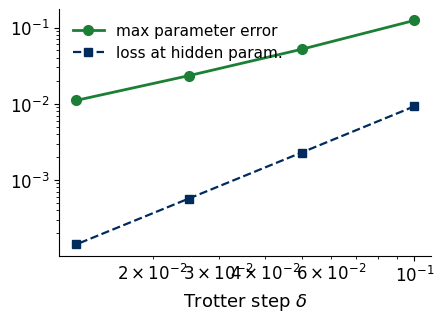

optional section: 8 s, whole notebook: 15 s


In [10]:
t0 = time.perf_counter()
subsets = {"1 pair": [(0, 0)], "5 pairs, 1 state": [(0, k) for k in range(K_PER)],
           "5 pairs, 3 states": [(0, 0), (0, 3), (1, 1), (1, 4), (2, 2)],
           "15 pairs, 3 states": [(m, k) for m in range(M) for k in range(K_PER)]}
budget = {}
for name, sel in subsets.items():
    # one "initial state" per pair keeps the loss code unchanged
    p0 = np.array([PSI0[m] for m, k in sel]); dat = np.array([[DATA[m, k]] for m, k in sel])
    st = np.array([[STEPS[m, k]] for m, k in sel])
    th, _, _, Lf = adam(make_loss(p0, dat, st), jnp.asarray(THETA0))
    budget[name] = (Lf, float(np.abs(th - THETA_HIDDEN).max()))
    print(f"{name:20s} final loss {Lf:.1e}   max |theta - hidden| {budget[name][1]:.3f}")

DELTAS = np.array([0.1, 0.05, 0.025, 0.0125])
trot = []
for d in DELTAS:
    st = np.rint(TIMES / d).astype(int)
    ls = make_loss(PSI0, DATA, st, d)
    th, _, _, Lf = adam(ls, jnp.asarray(THETA0))
    trot.append((float(ls(jnp.asarray(THETA_HIDDEN))), Lf, float(np.abs(th - THETA_HIDDEN).max())))
    print(f"delta = {d:6.4f}: loss at hidden {trot[-1][0]:.1e}, final loss {Lf:.1e}, max |theta - hidden| {trot[-1][2]:.3f}")
trot = np.array(trot)

fig, ax = plt.subplots(figsize=(4.8, 3.2))
ax.loglog(DELTAS, trot[:, 2], "o-", color=GREEN, lw=2, ms=7, label="max parameter error")
ax.loglog(DELTAS, trot[:, 0], "s--", color=NAVY, lw=1.6, ms=6, label="loss at hidden param.")
ax.set_xlabel(r"Trotter step $\delta$"); ax.legend(frameon=False, loc="upper left", fontsize=11)
save(fig, "fig_lab070d_trotter"); plt.show()
RESULTS["optional"] = {"budget": budget, "deltas": DELTAS.tolist(), "trotter": trot.tolist(),
                       "seconds": time.perf_counter() - t0}
RESULTS["total_seconds"] = time.perf_counter() - started
(RES / "lab070d_results.json").write_text(json.dumps(RESULTS, indent=2, default=float))
mac = {"Pairs": M * K_PER, "Delta": DELTA, "LossFinal": f"{L_FINAL:.1e}", "LossHidden": f"{L_HIDDEN:.1e}",
       "MaxErr": f"{np.abs(DEV).max():.2f}", "MaxNonEdge": f"{np.abs(THETA[:NE][~EDGE]).max():.2f}"}
(FIG / "nb_numbers_lab070d.tex").write_text("".join(f"\\providecommand{{\\labseventyd{k}}}{{{v}}}\n" for k, v in mac.items()))
print(f"optional section: {RESULTS['optional']['seconds']:.0f} s, whole notebook: {RESULTS['total_seconds']:.0f} s")

A single data pair is matched with a loss below that of the hidden parameters on the full data set, and yet the learned parameters deviate by almost $0.2$, more than three times the error of the full fit. One fidelity cannot fix ten numbers. Five times of a single initial state already bring the error close to that of the full set, and in this example spreading the pairs over three states or using all fifteen pairs improves it only slightly, because the remaining error is the Trotter bias. The Trotter scan shows the loss at the hidden parameters falling as $\delta^2$ and the parameter error falling roughly in proportion to $\delta$. Halving the step halves the bias of the learned Hamiltonian and doubles the depth of the circuit.

## 10. Exercises

1. Learn the transverse fields too. Replace the fixed $g$ by four trainable fields $g_i$ and check whether the fourteen parameters are still recovered from the fifteen data pairs.
2. Use a symmetric Trotter layer $e^{-i\delta\hat{\mathcal H}_V/2}e^{-i\delta\hat{\mathcal H}_E}e^{-i\delta\hat{\mathcal H}_V/2}$ and repeat the Trotter scan of Section 9. Determine how the parameter error now scales with $\delta$.
3. Replace every fidelity in the loss by a SWAP-test estimate $\tilde F=2n_0/S-1$ from $S$ simulated shots, with a new sample at every Adam step, and find the smallest $S$ for which the learned graph still shows the ring.
4. Start the training from the exact ground state $|E_0\rangle$ as the only initial state and explain the result with the argument of Section 5.
5. Change the hidden graph to a star with qubit 0 in the centre, keep the complete-graph model and check that the learned couplings reveal the star.

## 11. Summary

A quantum graph recurrent neural network places one qubit on every node of a graph and repeats one layer of gates, single-qubit rotations on the nodes followed by $\hat Z\hat Z$ interactions on the edges, with the same parameters in every layer. One layer is a Trotter step of a Hamiltonian whose fields and couplings are the parameters, so the whole network simulates the time evolution under a trainable Hamiltonian on a graph. We used it to learn a hidden transverse-field Ising Hamiltonian of four qubits from fifteen pairs of initial and time-evolved states, with the loss one minus the average fidelity, which a SWAP test measures on hardware. Starting from a random dense graph, Adam recovered the four couplings of the hidden ring and the four fields to within a few hundredths and drove the two absent couplings to about $10^{-2}$, so the learned graph revealed the hidden one. The learned model predicts the dynamics beyond the training times as well as the Trotterised evolution with the hidden parameters. The remaining parameter error is the bias of the Trotter step and shrinks in proportion to it, and a single data pair is not enough to identify the Hamiltonian. All numbers are exact state-vector results.

## References

[1] G. Verdon, T. McCourt, E. Luzhnica, V. Singh, S. Leichenauer, and J. Hidary, Quantum graph neural networks, arXiv:1909.12264 (2019), https://arxiv.org/abs/1909.12264

[2] H. F. Trotter, On the product of semi-groups of operators, Proc. Am. Math. Soc. 10, 545 (1959), https://doi.org/10.1090/S0002-9939-1959-0108732-6

[3] H. Buhrman, R. Cleve, J. Watrous, and R. de Wolf, Quantum fingerprinting, Phys. Rev. Lett. 87, 167902 (2001), https://doi.org/10.1103/PhysRevLett.87.167902

[4] D. P. Kingma and J. Ba, Adam: a method for stochastic optimization, arXiv:1412.6980 (2014), https://arxiv.org/abs/1412.6980

[5] N. Wiebe, C. Granade, C. Ferrie, and D. G. Cory, Hamiltonian learning and certification using quantum resources, Phys. Rev. Lett. 112, 190501 (2014), https://doi.org/10.1103/PhysRevLett.112.190501